In [1]:
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [9]:
files = sorted(glob.glob(r"results\sim_part_*.csv"))
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

print(f"Read: {len(df):,} rows")
print(df.head())

Read: 1,200,000 rows
   task_id  beta strategy  pct_reached  peak_spreaders  duration
0        0  0.01     none       35.380             421        62
1        0  0.01     none       38.450             370        80
2        0  0.01     none       46.546             434        93
3        0  0.01     none       45.952             478        81
4        0  0.01     none       48.304             409        76


In [12]:
# avg spread, median spread, outbreak probability (>20% of the network)
df["is_outbreak"] = df["pct_reached"] > 20.0

summary = (
    df.groupby(["beta", "strategy"])
    .agg(
        mean_reached=("pct_reached", "mean"),
        std_reached=("pct_reached", "std"),
        median_reached=("pct_reached", "median"),
        outbreak_prob=("is_outbreak", lambda x: x.mean() * 100),
        mean_peak=("peak_spreaders", "mean"),
    )
    .reset_index()
)

pivot_mean = summary.pivot(
    index="beta", columns="strategy", values="mean_reached"
)[["none", "random", "acquaintance", "hubs"]]
print(
    "\nAverage percentage of the infected network (%) with a 5% immunization budget:"
)
print(pivot_mean.round(2))


Average percentage of the infected network (%) with a 5% immunization budget:
strategy   none  random  acquaintance   hubs
beta                                        
0.010     38.99   34.16         26.45  19.03
0.015     57.08   51.56         42.66  36.81
0.020     67.20   61.68         53.49  49.55
0.030     77.62   72.12         64.66  63.32
0.050     86.84   81.14         73.82  74.75
0.080     92.37   86.72         79.70  81.64


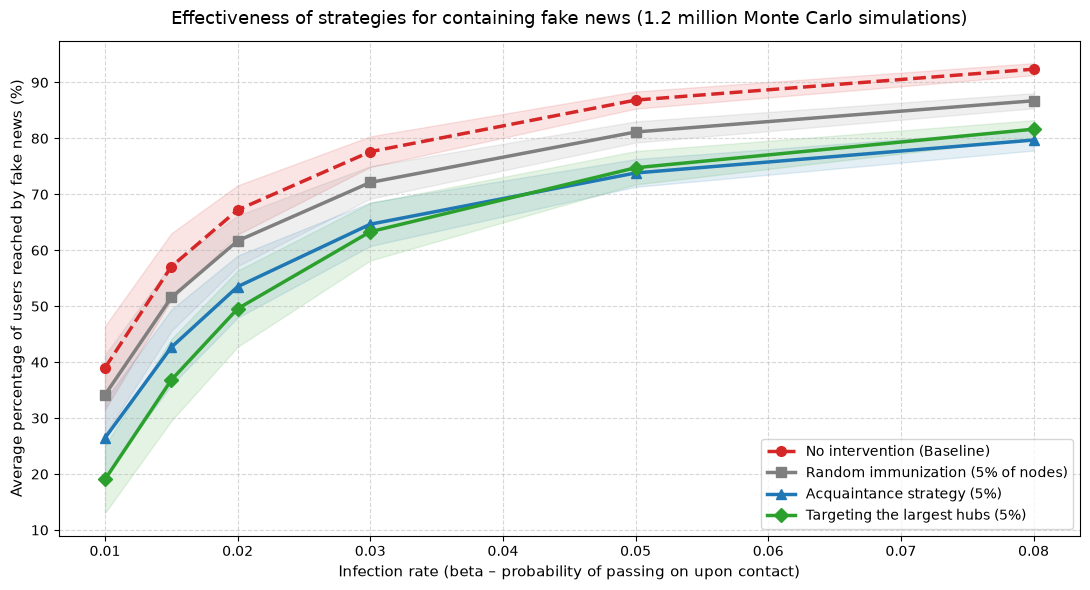

In [13]:
# strategy comparison plot
plt.figure(figsize=(11, 6))

labels_map = {
    "none": ("No intervention (Baseline)", "#d62728", "o", "--"),
    "random": ("Random immunization (5% of nodes)", "#7f7f7f", "s", "-"),
    "acquaintance": (
        "Acquaintance strategy (5%)",
        "#1f77b4",
        "^",
        "-",
    ),
    "hubs": ("Targeting the largest hubs (5%)", "#2ca02c", "D", "-"),
}

for strat in ["none", "random", "acquaintance", "hubs"]:
    sub = summary[summary["strategy"] == strat].sort_values("beta")
    label, color, marker, ls = labels_map[strat]

    plt.plot(
        sub["beta"],
        sub["mean_reached"],
        label=label,
        color=color,
        marker=marker,
        linestyle=ls,
        linewidth=2.5,
        markersize=7,
    )
    # Cień pokazujący odchylenie standardowe (rozrzut między przebiegami)
    plt.fill_between(
        sub["beta"],
        np.maximum(0, sub["mean_reached"] - sub["std_reached"] * 0.5),
        np.minimum(100, sub["mean_reached"] + sub["std_reached"] * 0.5),
        color=color,
        alpha=0.12,
    )

plt.title(
    "Effectiveness of strategies for containing fake news (1.2 million Monte Carlo simulations)",
    fontsize=13,
    pad=12,
)
plt.xlabel(
    "Infection rate (beta – probability of passing on upon contact)",
    fontsize=11,
)
plt.ylabel("Average percentage of users reached by fake news (%)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.savefig("images/strategy_comparison.png", dpi=200)
plt.show()

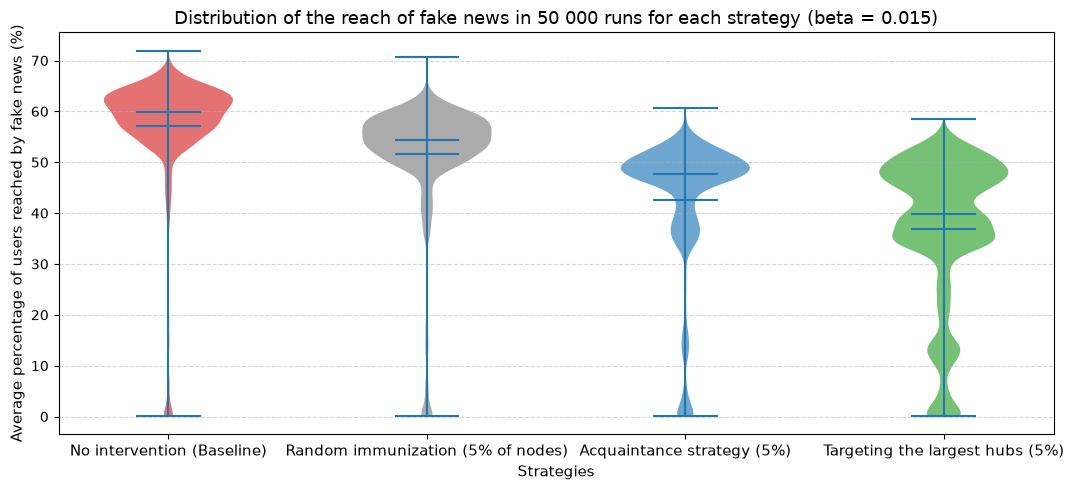

In [14]:
target_beta = 0.015
sub_beta = df[df["beta"] == target_beta]

plt.figure(figsize=(11, 5))
order = ["none", "random", "acquaintance", "hubs"]
names = [
    "No intervention (Baseline)",
    "Random immunization (5% of nodes)",
    "Acquaintance strategy (5%)",
    "Targeting the largest hubs (5%)",
]
colors = ["#d62728", "#7f7f7f", "#1f77b4", "#2ca02c"]

data_to_plot = [sub_beta[sub_beta["strategy"] == s]["pct_reached"] for s in order]

parts = plt.violinplot(data_to_plot, showmeans=True, showmedians=True)
for pc, color in zip(parts["bodies"], colors):
    pc.set_facecolor(color)
    pc.set_alpha(0.65)

plt.xticks([1, 2, 3, 4], names, fontsize=11)
plt.xlabel("Strategies", fontsize=11)
plt.ylabel("Average percentage of users reached by fake news (%)", fontsize=11)
plt.title(
    f"Distribution of the reach of fake news in 50 000 runs for each strategy (beta = {target_beta})",
    fontsize=13,
)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("images/distribution_violin.png", dpi=200)
plt.show()

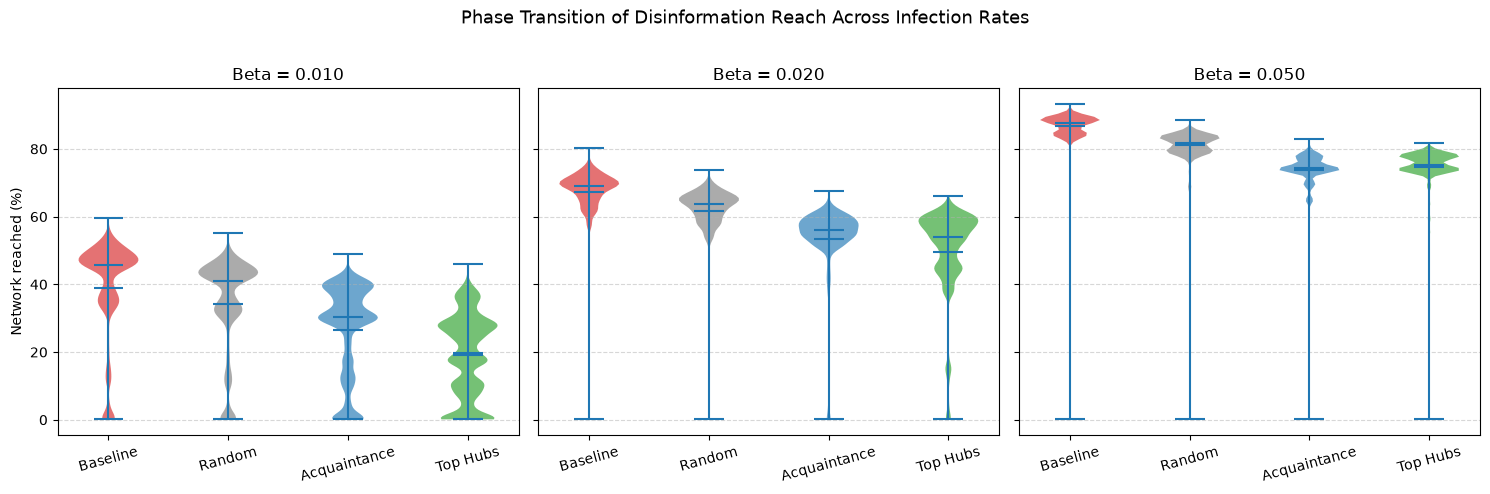

In [20]:
selected_betas = [0.010, 0.020, 0.050]
order = ["none", "random", "acquaintance", "hubs"]
names = ["Baseline", "Random", "Acquaintance", "Top Hubs"]
colors = ["#d62728", "#7f7f7f", "#1f77b4", "#2ca02c"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

for ax, b in zip(axes, selected_betas):
    sub = df[df["beta"] == b]
    data_to_plot = [sub[sub["strategy"] == s]["pct_reached"] for s in order]

    parts = ax.violinplot(data_to_plot, showmeans=True, showmedians=True)
    for pc, color in zip(parts["bodies"], colors):
        pc.set_facecolor(color)
        pc.set_alpha(0.65)

    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(names, rotation=15)
    ax.set_title(f"Beta = {b:.3f}", fontsize=12)
    ax.grid(axis="y", linestyle="--", alpha=0.5)

axes[0].set_ylabel("Network reached (%)")
fig.suptitle("Phase Transition of Disinformation Reach Across Infection Rates", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("images/beta_phase_transition.png", dpi=200, bbox_inches="tight")
plt.show()

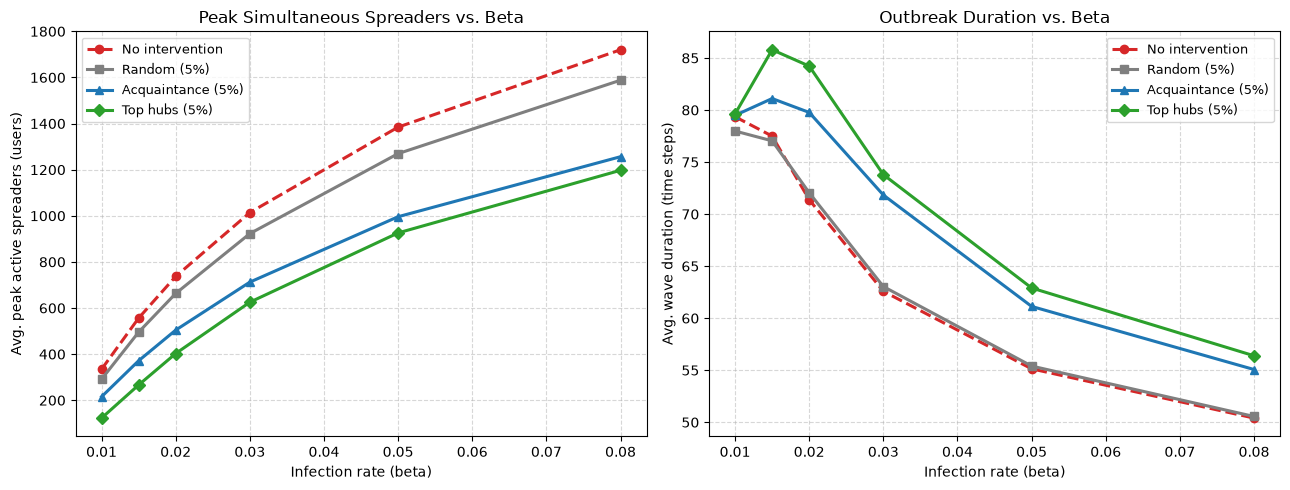

In [17]:
# Aggregating duration alongside peak_spreaders across all betas
dynamics_summary = (
    df.groupby(["beta", "strategy"])
    .agg(
        mean_peak=("peak_spreaders", "mean"),
        mean_duration=("duration", "mean"),
    )
    .reset_index()
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

labels_map = {
    "none": ("No intervention", "#d62728", "o", "--"),
    "random": ("Random (5%)", "#7f7f7f", "s", "-"),
    "acquaintance": ("Acquaintance (5%)", "#1f77b4", "^", "-"),
    "hubs": ("Top hubs (5%)", "#2ca02c", "D", "-"),
}

for strat in ["none", "random", "acquaintance", "hubs"]:
    sub = dynamics_summary[dynamics_summary["strategy"] == strat].sort_values("beta")
    label, color, marker, ls = labels_map[strat]

    # Left: Peak simultaneous spreaders
    ax1.plot(
        sub["beta"], sub["mean_peak"],
        label=label, color=color, marker=marker, linestyle=ls, linewidth=2.2
    )
    # Right: Wave duration
    ax2.plot(
        sub["beta"], sub["mean_duration"],
        label=label, color=color, marker=marker, linestyle=ls, linewidth=2.2
    )

ax1.set_title("Peak Simultaneous Spreaders vs. Beta", fontsize=12)
ax1.set_xlabel("Infection rate (beta)")
ax1.set_ylabel("Avg. peak active spreaders (users)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(fontsize=9)

ax2.set_title("Outbreak Duration vs. Beta", fontsize=12)
ax2.set_xlabel("Infection rate (beta)")
ax2.set_ylabel("Avg. wave duration (time steps)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig("images/beta_dynamics.png", dpi=200)
plt.show()

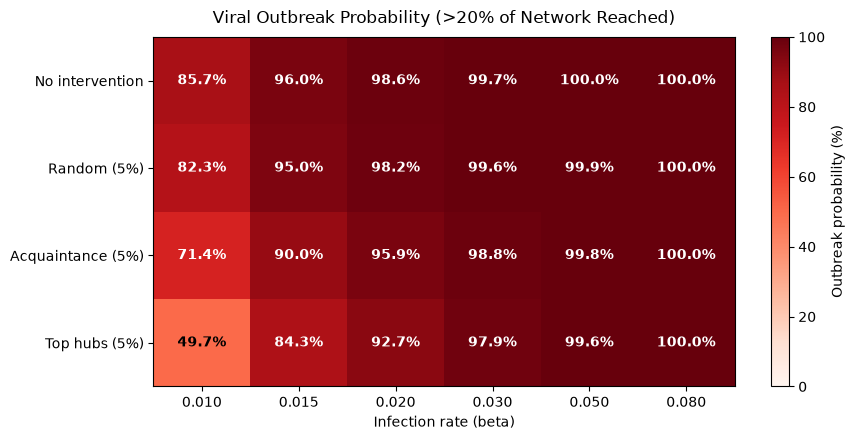

In [19]:
pivot_outbreak = summary.pivot(
    index="strategy", columns="beta", values="outbreak_prob"
).loc[["none", "random", "acquaintance", "hubs"]]

row_names = [
    "No intervention",
    "Random (5%)",
    "Acquaintance (5%)",
    "Top hubs (5%)",
]

fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(pivot_outbreak.values, cmap="Reds", aspect="auto", vmin=0, vmax=100)

ax.set_xticks(np.arange(len(pivot_outbreak.columns)))
ax.set_xticklabels([f"{b:.3f}" for b in pivot_outbreak.columns])
ax.set_yticks(np.arange(len(row_names)))
ax.set_yticklabels(row_names)

# Annotate each cell with exact percentage
for i in range(len(row_names)):
    for j in range(len(pivot_outbreak.columns)):
        val = pivot_outbreak.values[i, j]
        text_color = "white" if val > 55 else "black"
        ax.text(j, i, f"{val:.1f}%", ha="center", va="center", color=text_color, fontweight="bold")

ax.set_title("Viral Outbreak Probability (>20% of Network Reached)", fontsize=12, pad=10)
ax.set_xlabel("Infection rate (beta)")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Outbreak probability (%)")

plt.tight_layout()
plt.savefig("images/outbreak_heatmap.png", dpi=200)
plt.show()

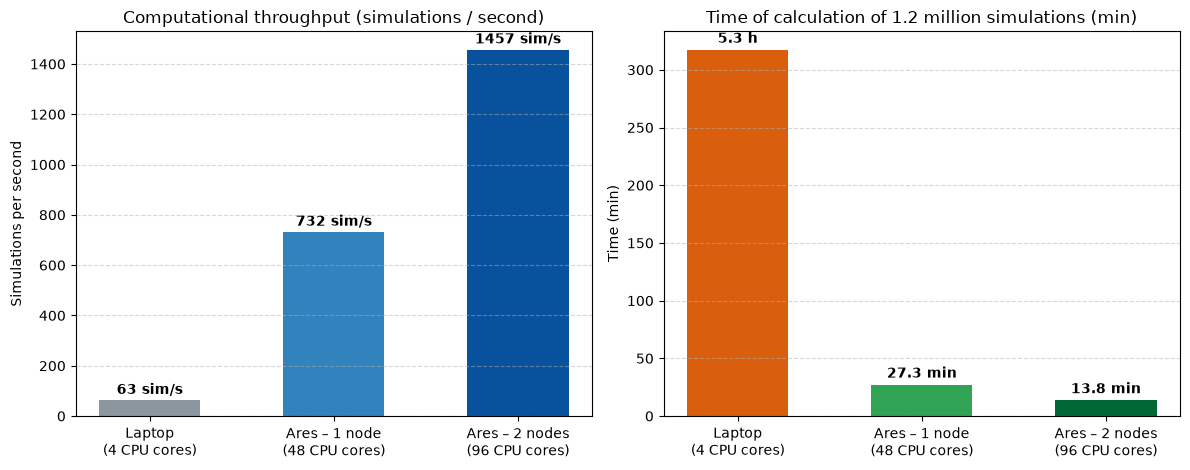

In [16]:
configs = [
    "Laptop\n(4 CPU cores)",
    "Ares – 1 node\n(48 CPU cores)",
    "Ares – 2 nodes\n(96 CPU cores)",
]
throughputs = [63, 732, 732 + 725]
times_min = [1200000 / 63 / 60, 1200000 / 732 / 60, 828.08 / 60]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

bars1 = ax1.bar(configs, throughputs, color=["#8c969e", "#3182bd", "#08519c"], width=0.55)
ax1.set_title("Computational throughput (simulations / second)", fontsize=12)
ax1.set_ylabel("Simulations per second")
ax1.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars1:
    h = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        h + 25,
        f"{int(h)} sim/s",
        ha="center",
        fontweight="bold",
    )

bars2 = ax2.bar(configs, times_min, color=["#d95f0e", "#31a354", "#006837"], width=0.55)
ax2.set_title("Time of calculation of 1.2 million simulations (min)", fontsize=12)
ax2.set_ylabel("Time (min)")
ax2.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    h = bar.get_height()
    label = f"{h/60:.1f} h" if h > 60 else f"{h:.1f} min"
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        h + 6,
        label,
        ha="center",
        fontweight="bold",
    )

plt.tight_layout()
plt.savefig("images/hpc_benchmark.png", dpi=200)
plt.show()